# Incorporación de 2024

El sistema pasa de trabajar con 2026 a trabajar con 2024 y 2026. Los archivos de 2024 vienen de la misma fuente de la TLC.

Salidas de la ejecución verificada del ejercicio 5. Los conteos brutos se reconfirmaron desde los metadatos Parquet y están en docs/resultados/ejercicio_5_conteos_metadatos.csv.


In [1]:
from pathlib import Path
import os
import sys
import platform
import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

raiz = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "scripts/laboratorio").is_dir())
sys.path.insert(0, str(raiz / "scripts"))
from laboratorio.sesion_consultas import Analisis
from laboratorio.parametros import Configuracion
from laboratorio.soporte_cuadernos import configurar_notebook, ejecutar_script, mostrar_indicador
from laboratorio.graficos import COLOR, NOMBRE, COLOR_ANIO, MESES, miles

configurar_notebook()
config = Configuracion.del_entorno()
analisis = Analisis(config, anios=(2024, 2026))
con = analisis.con
consulta = analisis.consulta


## 5.1 Cambio en el sistema de descarga

Los años se seleccionan mediante argumentos CLI: `python scripts/descargar_taxis.py --anios 2024` y `python scripts/validar_taxis.py --anios 2024 2026`. No se necesita editar la constante ANIOS. La URL, la carpeta de destino y la regla de archivos existentes se conservan.

## 5.2 a 5.4 Nueva descarga

La carpeta ya tenía los 16 archivos de 2026. La publicación oficial ofrece 24 archivos de 2024: 12 amarillos y 12 verdes. La primera ejecución omitió cinco enlaces porque sus atributos href tenían espacios finales; el parser ya fue corregido y los cinco archivos se incorporaron.

| Estado | Archivos | Detalle |
| --- | --- | --- |
| Descargados | 5 | Enlaces 2024 que no habían sido detectados |
| Ya existían | 20 | 19 Parquet de 2024 existentes y el catálogo de zonas |
| No publicados | 0 | Todos los enlaces 2024 detectados y accesibles |
| Fallidos | 0 | |

Los archivos de 2026 y los 19 archivos 2024 previos se conservaron y no se pidieron otra vez al servidor. Una nueva ejecución omite todos los archivos completos:

In [2]:
if os.environ.get("LAB8_EJECUTAR_RED", "0") == "1":
    ejecutar_script("descargar_taxis.py", "--anios", "2024", "2026")
else:
    print("Descarga omitida: se reutilizan los archivos ya verificados. Use LAB8_EJECUTAR_RED=1 para repetirla.")
analisis.crear_vistas()


Descarga omitida: se reutilizan los archivos ya verificados. Use LAB8_EJECUTAR_RED=1 para repetirla.


## 5.5 Verificación

La verificación compara data/raw con la lista de la TLC para 2024 y 2026.

In [3]:
if os.environ.get("LAB8_EJECUTAR_RED", "0") == "1":
    ejecutar_script("validar_taxis.py", "--anios", "2024", "2026")
else:
    print("Validación omitida: se reutiliza docs/resultados/verificacion_descarga.json.")
analisis.crear_vistas()


Validación omitida: se reutiliza docs/resultados/verificacion_descarga.json.


DuckDB confirma desde el pie de cada Parquet cuántos archivos, meses y registros hay por tipo y año.

In [4]:
consulta("integracion/01_inventario_anual.sql")

-- Archivos, meses y registros por tipo de taxi y año, según el pie de cada Parquet
SELECT
    regexp_extract(file_name, '(yellow|green)_tripdata', 1) AS tipo,
    regexp_extract(file_name, '_(\d{4})-\d{2}\.parquet', 1)::INT AS anio,
    count(*) AS archivos,
    min(regexp_extract(file_name, '(\d{4}-\d{2})\.parquet', 1)) AS primer_mes,
    max(regexp_extract(file_name, '(\d{4}-\d{2})\.parquet', 1)) AS ultimo_mes,
    sum(num_rows)::BIGINT AS registros
FROM parquet_file_metadata(['/workspace/data/raw/yellow/2024/yellow_tripdata_2024-01.parquet', '/workspace/data/raw/yellow/2024/yellow_tripdata_2024-02.parquet', '/workspace/data/raw/yellow/2024/yellow_tripdata_2024-03.parquet', '/workspace/data/raw/yellow/2024/yellow_tripdata_2024-04.parquet', '/workspace/data/raw/yellow/2024/yellow_tripdata_2024-05.parquet', '/workspace/data/raw/yellow/2024/yellow_tripdata_2024-06.parquet', '/workspace/data/raw/yellow/2024/yellow_tripdata_2024-07.parquet', '/workspace/data/raw/yellow/2024/yellow_tripda

-- 0.23 s


,tipo,anio,archivos,primer_mes,ultimo_mes,registros
0,yellow,2024,12,2024-01,2024-12,41169720
1,yellow,2026,8,2026-01,2026-08,29703355
2,green,2024,12,2024-01,2024-12,660218
3,green,2026,8,2026-01,2026-08,337114


Los 24 archivos de 2024 suman 41,169,720 viajes amarillos y 660,218 verdes, es decir, 41,829,938 registros. Los 16 archivos de 2026 suman 30,040,469 registros. El total bruto combinado es 71,870,407 registros; la consulta de viajes válidos aplica además las reglas de calidad.

## 5.6 Consulta conjunta de 2024 y 2026

Una sola consulta sobre la vista viajes_validos, que lee todos los Parquet de data/raw, entrega los indicadores de cada año.

In [5]:
consulta("integracion/02_resumen_por_anio.sql")

-- Viajes válidos e indicadores por año y tipo de taxi, en una sola consulta sobre todos los años
SELECT
    year(periodo) AS anio,
    taxi,
    count(DISTINCT periodo) AS meses,
    count(*) AS viajes,
    round(count(*) / count(DISTINCT CAST(pickup_datetime AS DATE))) AS viajes_por_dia,
    round(avg(trip_distance), 2) AS distancia_prom,
    round(avg(total_amount), 2) AS total_prom,
    round(100 * avg((coalesce(payment_type, 0) = 0)::INT), 1) AS pct_flex_fare,
    round(100 * avg((cbd_congestion_fee > 0)::INT), 1) AS pct_con_cargo_cbd
FROM viajes_validos
GROUP BY anio, taxi
ORDER BY taxi DESC, anio



-- 15.62 s


,anio,taxi,meses,viajes,viajes_por_dia,distancia_prom,total_prom,pct_flex_fare,pct_con_cargo_cbd
0,2024,yellow,12,39673306,108397.0,3.42,28.63,9.3,0.0
1,2026,yellow,8,28223766,116147.0,3.51,30.24,24.9,72.4
2,2024,green,12,618891,1691.0,2.93,24.06,3.8,0.0
3,2026,green,8,321395,1323.0,3.35,25.36,14.7,8.5


Para comparar meses iguales se agrupa por mes y año.

In [6]:
meses = consulta("integracion/03_comparacion_meses.sql")
meses.pivot_table(index="mes", columns=["taxi", "anio"], values="viajes_por_dia")

-- Viajes por día de cada mes, para comparar el mismo mes en distintos años
SELECT
    taxi,
    month(periodo) AS mes,
    year(periodo) AS anio,
    viajes_por_dia
FROM viajes_por_mes
ORDER BY taxi DESC, mes, anio



-- 12.49 s


taxi   green            yellow          
anio    2024    2026      2024      2026
mes                                     
1     1713.0  1244.0   92478.0  113401.0
2     1733.0  1271.0   99959.0  114619.0
3     1739.0  1365.0  110873.0  121346.0
4     1759.0  1405.0  113711.0  122437.0
5     1848.0  1382.0  116606.0  126158.0
6     1716.0  1407.0  114179.0  121515.0
7     1558.0  1264.0   95842.0  107907.0
8     1562.0  1243.0   92403.0  102022.0
9     1701.0     NaN  116040.0       NaN
10    1709.0     NaN  118681.0       NaN
11    1630.0     NaN  116906.0       NaN
12    1626.0     NaN  113422.0       NaN

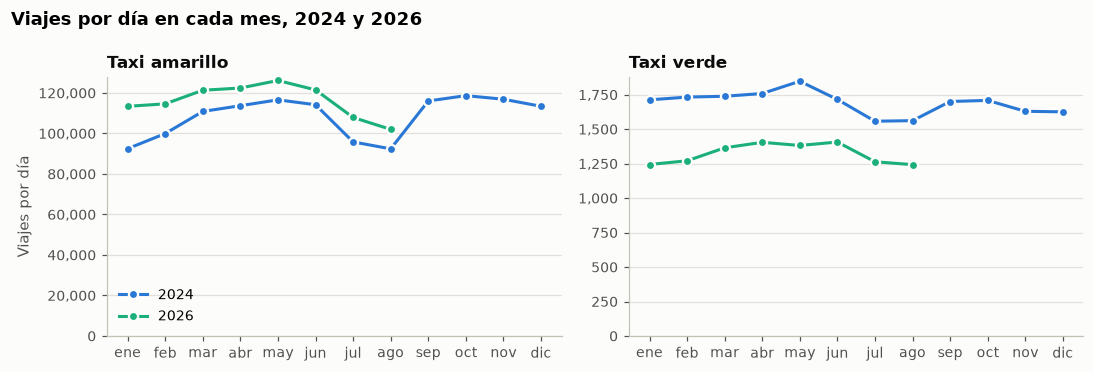

In [7]:
fig, ejes = plt.subplots(1, 2, figsize=(10, 3.4))
for eje, taxi in zip(ejes, ["yellow", "green"]):
    for anio, d in meses[meses.taxi == taxi].groupby("anio"):
        eje.plot(d.mes, d.viajes_por_dia, color=COLOR_ANIO[anio], label=str(anio), marker="o", markersize=6,
                 markeredgecolor="#fcfcfb", markeredgewidth=1.5)
    eje.set_title(f"Taxi {NOMBRE[taxi].lower()}")
    eje.set_xticks(range(1, 13), MESES)
    eje.set_ylim(bottom=0)
    eje.yaxis.set_major_formatter(miles)
ejes[0].set_ylabel("Viajes por día")
ejes[0].legend(loc="lower left")
fig.suptitle("Viajes por día en cada mes, 2024 y 2026", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()

En los meses comparables enero-agosto, los amarillos registran más viajes por día en 2026 que en 2024 (aproximadamente 5%-23% según el mes). En cambio, los verdes registran menos viajes por día en 2026 que en 2024 (aproximadamente 19%-29%). Estas diferencias son descriptivas y no prueban causalidad.

## 5.7 Consultas anteriores con el conjunto ampliado

Se ejecutan las consultas de inspección y exploración sobre las vistas ampliadas. La revisión devuelve estado, filas y tiempo sin cargar resultados masivos en pandas.

In [8]:
revision = analisis.revisar_consultas("integracion/*.sql")
assert revision.estado.eq("ok").all(), revision[revision.estado.ne("ok")]
revision


,consulta,estado,filas,segundos
0,integracion/01_inventario_anual.sql,ok,4,0.1862
1,integracion/02_resumen_por_anio.sql,ok,4,15.6695
2,integracion/03_comparacion_meses.sql,ok,40,11.9279
3,integracion/04_efecto_nulos_cbd.sql,ok,3,1.5969


Las consultas terminan sin error cuando se ejecutan sobre las vistas normalizadas. Eso se debe a la decisión de leer con union_by_name. Los archivos de 2024 no tienen cbd_congestion_fee ni request_source en todos los esquemas; las columnas opcionales se agregan explícitamente antes de normalizar:

In [9]:
consulta("inspeccion/05_conciliacion_esquemas.sql")

-- Columnas que DuckDB expone al leer todos los archivos amarillos con y sin union_by_name
SELECT
    'sin union_by_name' AS lectura,
    count(*) AS columnas,
    list_contains(list(column_name), 'request_source') AS incluye_request_source
FROM (DESCRIBE SELECT * FROM read_parquet(['/workspace/data/raw/yellow/2024/yellow_tripdata_2024-01.parquet', '/workspace/data/raw/yellow/2024/yellow_tripdata_2024-02.parquet', '/workspace/data/raw/yellow/2024/yellow_tripdata_2024-03.parquet', '/workspace/data/raw/yellow/2024/yellow_tripdata_2024-04.parquet', '/workspace/data/raw/yellow/2024/yellow_tripdata_2024-05.parquet', '/workspace/data/raw/yellow/2024/yellow_tripdata_2024-06.parquet', '/workspace/data/raw/yellow/2024/yellow_tripdata_2024-07.parquet', '/workspace/data/raw/yellow/2024/yellow_tripdata_2024-08.parquet', '/workspace/data/raw/yellow/2024/yellow_tripdata_2024-09.parquet', '/workspace/data/raw/yellow/2024/yellow_tripdata_2024-10.parquet', '/workspace/data/raw/yellow/2024/yellow_tripda

-- 0.40 s


,lectura,columnas,incluye_request_source
0,sin union_by_name,19,False
1,con union_by_name,21,True


In [10]:
print("La compatibilidad de esquemas se valida mediante las vistas union_by_name y la conciliación anterior.")

La compatibilidad de esquemas se valida mediante las vistas union_by_name y la conciliación anterior.


Sin union_by_name, DuckDB expone 19 columnas y cualquier consulta que use cbd_congestion_fee falla.

Que una consulta no falle tampoco garantiza que su resultado tenga sentido. cbd_congestion_fee es nula en todo 2024 porque el cargo empezó el 5 de enero de 2025, y los promedios de SQL ignoran los nulos. La siguiente consulta mide ese efecto sobre los archivos amarillos, sin pasar por la vista.

In [11]:
consulta("integracion/04_efecto_nulos_cbd.sql")

-- Porcentaje de viajes amarillos con cargo CBD, ignorando los nulos de 2024 o tomándolos como 0
WITH crudos AS (
    SELECT regexp_extract(filename, '_(\d{4})-\d{2}\.parquet', 1) AS anio, cbd_congestion_fee
    FROM yellow_crudos
)
SELECT
    coalesce(anio, 'todos') AS anio,
    count(*) AS viajes,
    count(cbd_congestion_fee) AS con_valor,
    round(100 * avg((cbd_congestion_fee > 0)::INT), 1) AS pct_ignorando_nulos,
    round(100 * avg((coalesce(cbd_congestion_fee, 0) > 0)::INT), 1) AS pct_nulos_como_0
FROM crudos
GROUP BY ROLLUP (anio)
ORDER BY grouping(anio), anio



-- 1.83 s


,anio,viajes,con_valor,pct_ignorando_nulos,pct_nulos_como_0
0,2024,41169720,0,NaN,0.0
1,2026,29703355,29703355,71.8,71.8
2,todos,70873075,29703355,71.8,30.1


El renglón `todos` de la consulta anterior suma **70,873,075 registros exclusivamente yellow** de 2024 y 2026; no es el total general. El total bruto de ambos tipos es **71,870,407** (2024: 41,829,938; 2026: 30,040,469).

En los archivos amarillos, el 71.8% de los viajes de 2026 tiene un cargo CBD positivo y 2024 no tiene valores en esa columna. Al tratar los nulos de 2024 como cero, el porcentaje combinado es 30.1%; no debe interpretarse como una tasa de pago comparable entre años.

La corrección se hizo en sql/normalizacion_viajes.sql y no en cada consulta: la vista viajes entrega coalesce(cbd_congestion_fee, 0). Con eso la comparación de tipos y la composición del total del ejercicio 4 quedan correctas sin tocarlas, y la comparación de tipos ahora muestra 30.1% en amarillos y 2.9% en verdes para los dos años. request_source se deja nula antes de junio de 2026, porque ahí el dato no existe y no equivale a cero.

Las demás consultas no necesitan cambios, pero las que no agrupan por periodo ahora mezclan dos años. Para comparar años están las consultas de sql/integracion, que agregan el año como dimensión.

## 5.8 Consultas de validación

| Archivo | Qué valida |
| --- | --- |
| integracion/01_inventario_anual.sql | Archivos, meses y registros por tipo y año |
| integracion/02_resumen_por_anio.sql | Que una sola consulta lea los dos años y entregue indicadores por año |
| integracion/03_comparacion_meses.sql | Que los meses de 2024 y 2026 se comparen en la misma consulta |
| integracion/04_efecto_nulos_cbd.sql | El efecto de una columna que no existe en todos los años |

La celda de 5.7 ejecuta las cuatro consultas de sql/integracion y registra estado, filas y tiempo.

## 5.9 Diseño que permite agregar archivos

- Todas las lecturas usan un comodín por tipo y año dentro de data/raw. Un año nuevo es una carpeta nueva y entra en la siguiente consulta.
- La opción union_by_name tolera columnas que aparecen o desaparecen entre años, como cbd_congestion_fee y request_source.
- Las consultas del análisis leen las vistas de sql/normalizacion_viajes.sql. Un cambio de esquema se corrige ahí una vez, como el coalesce de este ejercicio.
- El periodo sale del nombre del archivo, así que cada viaje queda en el mes publicado aunque traiga una fecha errónea, y las consultas por mes separan años sin cambios.
- Los años a descargar y validar se seleccionan con `--anios` en la CLI. El script omite lo que existe y reporta lo no publicado, y la verificación compara contra la lista de la TLC.
- Cada consulta está en un archivo de sql y se puede volver a ejecutar completa, como en 5.7.

In [12]:
analisis.cerrar()
